# 17 — Day-30 Hyperparameter Tuning for Random Forest and Gradient Boosting

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

Hank Butler's fourth recommendation was: *"Tune Hyperparameters: Perform hyperparameter tuning using grid or randomized
search for ensemble models."*

Notebook 12 used Random Forest and Gradient Boosting with one fixed setting each. Here I test a small grid of settings
for each model and check whether the best setting (chosen by cross-validation) improves the results.

- **Features for the ensembles:** exactly as in notebook 12: the 7 count features + the 15 selected activity indicators.
  No new features.
- **Reference:** Logistic Regression model **C** from notebook 14. C uses a **different feature set** (it also has the
  activity groups and the progress feature), so a difference between C and the ensembles cannot be explained by tuning
  alone.

Everything else is unchanged: historically completed cases, the recorded activity span, the 63-day threshold, day-30
eligibility (a retrospective rule), the random split (677 / 161) and the temporal split (617 / 168).

## 2. Load the Data and Build the Day-30 Cohort

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)
case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data["long_case"] = (case_data["duration_days"] > 63).astype(int)

case_data["prediction_time"] = case_data["first_event"] + pd.Timedelta(days=30)
active = case_data[case_data["last_event"] > case_data["prediction_time"]]

print("Completed cases:", len(case_data))
print("Day-30 eligible cases:", len(active))

Completed cases: 956
Day-30 eligible cases: 838


## 3. Shared Helpers (Copied Unchanged from Notebook 14)

These cells are exactly the code of notebook 14. `make_X(..., "A. Original", ...)` builds the notebook 12 features
(7 counts + 15 activity indicators); `make_X(..., "C. Combined", ...)` builds the features of model C.

In [3]:
def add_activity_groups(events):
    # the group is the prefix of the activity code, e.g. "02_DRZ" from "02_DRZ_010"
    events = events.copy()
    events["activity_group"] = events["concept:name"].str.extract(r"^(\d{2}_[A-Z0-9]+)_")[0]

    # for the main process 01_HOOFD, add the first digit of the number: "01_HOOFD_065_1" -> "01_HOOFD_0xx"
    is_main = events["activity_group"] == "01_HOOFD"
    first_digit = events.loc[is_main, "concept:name"].str[9]   # "01_HOOFD_" has 9 characters
    events.loc[is_main, "activity_group"] = "01_HOOFD_" + first_digit + "xx"
    return events


grouped_log = add_activity_groups(df)
print("Activity codes:", grouped_log["concept:name"].nunique())
print("Activity groups:", grouped_log["activity_group"].nunique())
print("Events without a group:", grouped_log["activity_group"].isna().sum())

Activity codes: 398
Activity groups: 28
Events without a group: 0


**Keep only the events up to each case's day-30 cutoff.**

In [4]:
def events_by_day30(event_table, cases):
    # keep only events of the given cases that happened on or before that case's day-30 cutoff
    events = event_table[event_table["case:concept:name"].isin(cases.index)].copy()
    events["prediction_time"] = events["case:concept:name"].map(cases["prediction_time"])
    events["first_event"] = events["case:concept:name"].map(cases["first_event"])
    first30 = events[events["time:timestamp"] <= events["prediction_time"]].copy()
    first30["day"] = (first30["time:timestamp"] - first30["first_event"]).dt.total_seconds() / (24 * 60 * 60)
    return first30

**The seven count features** (two of them are exact combinations of others, kept for continuity).

In [5]:
count_columns = [
    "events_first30",
    "unique_activities_first30",
    "unique_resources_first30",
    "repeated_activities_first30",
    "events_first15",
    "events_days16_30",
    "days_since_last_event",
]


def count_features(first30, cases):
    first30 = first30.copy()
    first30["in_first15"] = first30["day"] <= 15
    features = first30.groupby("case:concept:name").agg(
        events_first30=("concept:name", "size"),
        unique_activities_first30=("concept:name", "nunique"),
        unique_resources_first30=("org:resource", "nunique"),
        events_first15=("in_first15", "sum"),
        last_event_by_day30=("time:timestamp", "max"),
    )
    features["repeated_activities_first30"] = features["events_first30"] - features["unique_activities_first30"]
    features["events_days16_30"] = features["events_first30"] - features["events_first15"]
    features["days_since_last_event"] = (
        cases.loc[features.index, "prediction_time"] - features["last_event_by_day30"]
    ).dt.total_seconds() / (24 * 60 * 60)
    return features[count_columns]

**Apply the helpers** to all eligible cases and check that no event after the cutoff was used.

In [6]:
first30 = add_activity_groups(events_by_day30(df, active))
counts = count_features(first30, active)
y = active.loc[counts.index, "long_case"]

print("Events recorded by day 30:", len(first30))
print("Latest event used, in days after the case start:", first30["day"].max())
print("Every event used is on or before its case's cutoff:", (first30["time:timestamp"] <= first30["prediction_time"]).all())
print("Activity groups recorded by day 30:", first30["activity_group"].nunique())

Events recorded by day 30: 14551
Latest event used, in days after the case start: 30.0
Every event used is on or before its case's cutoff: True
Activity groups recorded by day 30: 23


**The 15 original activity indicators** (selected on training cases only).

In [7]:
def select_activities(first30, case_ids):
    # activity codes recorded in 10-90% of the given cases, at most 15, most frequent first (ties by code)
    events = first30[first30["case:concept:name"].isin(case_ids)]
    share = events.groupby("concept:name")["case:concept:name"].nunique() / len(case_ids) * 100
    share = share.rename("train_cases_pct").reset_index()
    share = share[(share["train_cases_pct"] >= 10) & (share["train_cases_pct"] <= 90)]
    share = share.sort_values(["train_cases_pct", "concept:name"], ascending=[False, True])
    return share.head(15)["concept:name"].tolist()


def activity_flags(first30, activities, case_ids):
    # 1 if the activity was recorded by day 30 in that case, otherwise 0
    flags = pd.DataFrame(index=case_ids)
    for activity in activities:
        cases_with_activity = first30.loc[first30["concept:name"] == activity, "case:concept:name"].unique()
        flags["act_" + activity] = flags.index.isin(cases_with_activity).astype(int)
    return flags

**The group indicators and the progress feature** (used only by model C).

In [8]:
def select_groups(first30, case_ids):
    # activity groups recorded by day 30 in at least 5% of the given cases, except 01_HOOFD_0xx
    events = first30[first30["case:concept:name"].isin(case_ids)]
    share = events.groupby("activity_group")["case:concept:name"].nunique() / len(case_ids) * 100
    groups = share[share >= 5].index.tolist()
    groups.remove("01_HOOFD_0xx")
    return sorted(groups)

In [9]:
def group_flags(first30, groups, case_ids):
    # 1 if the group was recorded by day 30 in that case, otherwise 0
    flags = pd.DataFrame(index=case_ids)
    for group in groups:
        cases_with_group = first30.loc[first30["activity_group"] == group, "case:concept:name"].unique()
        flags["grp_" + group] = flags.index.isin(cases_with_group).astype(int)

    # every rare group (not selected and not 01_HOOFD_0xx) goes into one column
    rare_events = first30[~first30["activity_group"].isin(groups + ["01_HOOFD_0xx"])]
    flags["grp_other_group"] = flags.index.isin(rare_events["case:concept:name"].unique()).astype(int)
    return flags

In [10]:
def highest_main_stage(first30, case_ids):
    # highest first digit of a 01_HOOFD code recorded by day 30, e.g. 4 for "01_HOOFD_4xx"
    main_events = first30[first30["activity_group"].str.startswith("01_HOOFD_")]
    stages = main_events["activity_group"].str[9].astype(int)
    highest = stages.groupby(main_events["case:concept:name"]).max()
    return highest.reindex(case_ids).fillna(0).astype(int).rename("highest_main_stage")

**Feature tables**, and the Logistic Regression and scores from notebook 14.

In [11]:
def make_X(case_ids, approach, activities, groups):
    X = counts.loc[case_ids]
    if approach in ["A. Original", "C. Combined"]:
        X = X.join(activity_flags(first30, activities, case_ids))
    if approach in ["B. Grouped", "C. Combined"]:
        X = X.join(group_flags(first30, groups, case_ids))
        X = X.join(highest_main_stage(first30, case_ids))
    return X

In [12]:
def fit_logistic_regression(X_train, y_train):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)


def score(model, X, y_true):
    predictions = model.predict(X)
    return {
        "ROC-AUC": roc_auc_score(y_true, model.predict_proba(X)[:, 1]),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions),
        "Cases flagged long": int(predictions.sum()),
    }

## 4. The Two Splits (Same as Notebooks 10–16)

In [13]:
day14_cases = case_data[case_data["last_event"] > case_data["first_event"] + pd.Timedelta(days=14)]
original_train_ids, original_test_ids = train_test_split(
    day14_cases.index, test_size=0.20, random_state=42, stratify=day14_cases["long_case"]
)

random_train_ids = [case for case in original_train_ids if case in active.index]
random_test_ids = [case for case in original_test_ids if case in active.index]

print("Random training cases:", len(random_train_ids), "| long:", y.loc[random_train_ids].sum())
print("Random test cases:", len(random_test_ids), "| long:", y.loc[random_test_ids].sum())
print("Overlap:", len(set(random_train_ids) & set(random_test_ids)))

Random training cases: 677 | long: 377
Random test cases: 161 | long: 95
Overlap: 0


In [14]:
sorted_cases = active.sort_values("prediction_time", kind="stable")
boundary = sorted_cases["prediction_time"].iloc[int(len(sorted_cases) * 0.8)]

temporal_test = sorted_cases[sorted_cases["prediction_time"] >= boundary]
candidates = sorted_cases[sorted_cases["prediction_time"] < boundary]
temporal_train = candidates[(candidates["last_event"] < boundary) & (candidates["end_date"] < boundary)]
temporal_train_ids, temporal_test_ids = temporal_train.index, temporal_test.index

print("Boundary:", boundary)
print("Temporal training cases:", len(temporal_train_ids), "| long:", y.loc[temporal_train_ids].sum())
print("Temporal test cases:", len(temporal_test_ids), "| long:", y.loc[temporal_test_ids].sum())
print("Overlap:", len(set(temporal_train_ids) & set(temporal_test_ids)))

Boundary: 2013-10-25 22:00:00+00:00
Temporal training cases: 617 | long: 328
Temporal test cases: 168 | long: 100
Overlap: 0


## 5. The Settings to Compare

**Original settings (notebook 12)**, kept as reference configurations:

- Random Forest: `n_estimators=100`, `max_depth=4`, `min_samples_leaf=10`
- Gradient Boosting: `n_estimators=100`, `learning_rate=0.05`, `max_depth=2`, `min_samples_leaf=10`

**Grids (fixed before running anything, not changed afterwards):**

- **Random Forest:** `n_estimators` = 100 or 200, `max_depth` = 3, 5 or None, `min_samples_leaf` = 1 or 3
  (12 combinations).
  - `n_estimators`: how many trees are averaged;
  - `max_depth`: how many questions each tree may ask in a row (None = no limit);
  - `min_samples_leaf`: the smallest number of training cases allowed in one leaf (end group) of a tree.
- **Gradient Boosting:** `n_estimators` = 50 or 100, `learning_rate` = 0.05 or 0.1, `max_depth` = 2 or 3
  (8 combinations).
  - `n_estimators`: how many small trees are added one after another;
  - `learning_rate`: how big a correction each new tree makes;
  - `max_depth`: how deep each small tree may grow.

Settings that are not in a grid keep scikit-learn's default values. Note that this means `min_samples_leaf=1` in the
Gradient Boosting grid, while the original Gradient Boosting used 10. Every model uses `random_state=42`.

In [15]:
rf_grid = []
for n_estimators in [100, 200]:
    for max_depth in [3, 5, None]:
        for min_samples_leaf in [1, 3]:
            rf_grid.append({"n_estimators": n_estimators, "max_depth": max_depth, "min_samples_leaf": min_samples_leaf})

gb_grid = []
for n_estimators in [50, 100]:
    for learning_rate in [0.05, 0.1]:
        for max_depth in [2, 3]:
            gb_grid.append({"n_estimators": n_estimators, "learning_rate": learning_rate, "max_depth": max_depth})

rf_original = {"n_estimators": 100, "max_depth": 4, "min_samples_leaf": 10}
gb_original = {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 2, "min_samples_leaf": 10}

print("Random Forest combinations:", len(rf_grid))
print("Gradient Boosting combinations:", len(gb_grid))

Random Forest combinations: 12
Gradient Boosting combinations: 8


**Fit one ensemble model with given settings.** `**settings` passes the dictionary entries as keyword arguments, for
example `{"max_depth": 3}` becomes `max_depth=3`.

In [16]:
def fit_random_forest(X_train, y_train, settings):
    return RandomForestClassifier(**settings, random_state=42).fit(X_train, y_train)


def fit_gradient_boosting(X_train, y_train, settings):
    return GradientBoostingClassifier(**settings, random_state=42).fit(X_train, y_train)

## 6. Decision Rule (Fixed Before Looking at the Test Sets)

For each model type, the **tuned** setting is the grid combination with the **highest mean cross-validation ROC-AUC** on
the random training cases (if two are equal, the first one in the grid). The test sets are not used for any choice.

## 7. Cross-Validation on the Random Training Cases

Same folds as notebooks 10–16. In every fold, the 15 activities (and, for model C, the groups) are selected on that
fold's training part only. Every model in a fold uses the same features, so only the settings differ.

In [17]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_index = pd.Index(random_train_ids)   # lets us turn fold positions into case IDs

cv_rows = []
for fold, (fit_positions, val_positions) in enumerate(folds.split(train_index, y.loc[train_index]), start=1):
    fit_ids = train_index[fit_positions]
    val_ids = train_index[val_positions]
    y_fit, y_val = y.loc[fit_ids], y.loc[val_ids]

    # selection on the fold's training part only
    activities = select_activities(first30, fit_ids)
    groups = select_groups(first30, fit_ids)
    X_fit = make_X(fit_ids, "A. Original", activities, groups)
    X_val = make_X(val_ids, "A. Original", activities, groups)

    model = fit_random_forest(X_fit, y_fit, rf_original)
    cv_rows.append({"Fold": fold, "Model": "Random Forest", "Settings": "original", **score(model, X_val, y_val)})
    for number, settings in enumerate(rf_grid, start=1):
        model = fit_random_forest(X_fit, y_fit, settings)
        cv_rows.append({"Fold": fold, "Model": "Random Forest", "Settings": f"grid {number}", **score(model, X_val, y_val)})

    model = fit_gradient_boosting(X_fit, y_fit, gb_original)
    cv_rows.append({"Fold": fold, "Model": "Gradient Boosting", "Settings": "original", **score(model, X_val, y_val)})
    for number, settings in enumerate(gb_grid, start=1):
        model = fit_gradient_boosting(X_fit, y_fit, settings)
        cv_rows.append({"Fold": fold, "Model": "Gradient Boosting", "Settings": f"grid {number}", **score(model, X_val, y_val)})

    model_c = fit_logistic_regression(make_X(fit_ids, "C. Combined", activities, groups), y_fit)
    X_val_c = make_X(val_ids, "C. Combined", activities, groups)
    cv_rows.append({"Fold": fold, "Model": "Logistic Regression C", "Settings": "notebook 14", **score(model_c, X_val_c, y_val)})

cv_results = pd.DataFrame(cv_rows)
print("Models scored:", len(cv_results), "(5 folds x", len(cv_results) // 5, "models)")

Models scored: 115 (5 folds x 23 models)


### All Random Forest combinations (cross-validation ROC-AUC)

In [18]:
rf_cv = cv_results[cv_results["Model"] == "Random Forest"].groupby("Settings", sort=False)["ROC-AUC"].agg(["mean", "std"])
rf_table = pd.DataFrame([rf_original] + rf_grid, index=rf_cv.index)
rf_table["max_depth"] = [str(settings["max_depth"]) for settings in [rf_original] + rf_grid]   # show None as text
rf_table["CV ROC-AUC mean"] = rf_cv["mean"]
rf_table["CV ROC-AUC std"] = rf_cv["std"]
rf_table.round(3)

,n_estimators,max_depth,min_samples_leaf,CV ROC-AUC mean,CV ROC-AUC std
Settings,,,,,
original,100,4,10,0.701,0.042
grid 1,100,3,1,0.704,0.042
grid 2,100,3,3,0.704,0.042
grid 3,100,5,1,0.719,0.031
grid 4,100,5,3,0.717,0.029
grid 5,100,None,1,0.672,0.019
grid 6,100,None,3,0.714,0.022
grid 7,200,3,1,0.700,0.038
grid 8,200,3,3,0.701,0.037


### All Gradient Boosting combinations (cross-validation ROC-AUC)

In [19]:
gb_cv = cv_results[cv_results["Model"] == "Gradient Boosting"].groupby("Settings", sort=False)["ROC-AUC"].agg(["mean", "std"])
gb_table = pd.DataFrame([gb_original] + gb_grid, index=gb_cv.index)
gb_table["min_samples_leaf"] = ["10"] + ["default (1)"] * len(gb_grid)   # the grid keeps the default value
gb_table["CV ROC-AUC mean"] = gb_cv["mean"]
gb_table["CV ROC-AUC std"] = gb_cv["std"]
gb_table.round(3)

,n_estimators,learning_rate,max_depth,min_samples_leaf,CV ROC-AUC mean,CV ROC-AUC std
Settings,,,,,,
original,100,0.05,2,10,0.684,0.044
grid 1,50,0.05,2,default (1),0.695,0.056
grid 2,50,0.05,3,default (1),0.710,0.029
grid 3,50,0.10,2,default (1),0.690,0.039
grid 4,50,0.10,3,default (1),0.705,0.023
grid 5,100,0.05,2,default (1),0.682,0.043
grid 6,100,0.05,3,default (1),0.704,0.030
grid 7,100,0.10,2,default (1),0.687,0.027
grid 8,100,0.10,3,default (1),0.688,0.032


**Choose the tuned settings** with the decision rule (grid combinations only, cross-validation only).

In [20]:
rf_best_name = rf_cv.drop("original")["mean"].idxmax()
gb_best_name = gb_cv.drop("original")["mean"].idxmax()
rf_tuned = rf_grid[int(rf_best_name.split()[1]) - 1]
gb_tuned = gb_grid[int(gb_best_name.split()[1]) - 1]

print("Tuned Random Forest:", rf_best_name, rf_tuned, "| CV ROC-AUC", round(rf_cv.loc[rf_best_name, "mean"], 3))
print("Tuned Gradient Boosting:", gb_best_name, gb_tuned, "| CV ROC-AUC", round(gb_cv.loc[gb_best_name, "mean"], 3))

Tuned Random Forest: grid 9 {'n_estimators': 200, 'max_depth': 5, 'min_samples_leaf': 1} | CV ROC-AUC 0.72
Tuned Gradient Boosting: grid 2 {'n_estimators': 50, 'learning_rate': 0.05, 'max_depth': 3} | CV ROC-AUC 0.71


**Note:** the best cross-validation score of a grid is a little **optimistic**, because it is the highest of 12 (or 8)
scores measured on the same folds. The test sets below check the chosen settings on cases that were not used for the
choice in this notebook.

## 8. Random Test and Temporal Test

Each model is fitted once on the training cases of a split and scored once on its test cases. For the temporal check,
the **same chosen settings** are fitted on the temporal training cases; nothing is chosen with the temporal test.

In [21]:
def evaluate_split(train_ids, test_ids):
    y_train, y_test = y.loc[train_ids], y.loc[test_ids]
    activities = select_activities(first30, train_ids)
    groups = select_groups(first30, train_ids)
    X_train = make_X(train_ids, "A. Original", activities, groups)
    X_test = make_X(test_ids, "A. Original", activities, groups)

    results = {}
    baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
    results["Majority baseline"] = score(baseline, X_test, y_test)
    results["Random Forest original"] = score(fit_random_forest(X_train, y_train, rf_original), X_test, y_test)
    results["Random Forest tuned"] = score(fit_random_forest(X_train, y_train, rf_tuned), X_test, y_test)
    results["Gradient Boosting original"] = score(fit_gradient_boosting(X_train, y_train, gb_original), X_test, y_test)
    results["Gradient Boosting tuned"] = score(fit_gradient_boosting(X_train, y_train, gb_tuned), X_test, y_test)

    model_c = fit_logistic_regression(make_X(train_ids, "C. Combined", activities, groups), y_train)
    results["Logistic Regression C"] = score(model_c, make_X(test_ids, "C. Combined", activities, groups), y_test)
    return pd.DataFrame(results).T

In [22]:
random_results = evaluate_split(random_train_ids, random_test_ids)
temporal_results = evaluate_split(temporal_train_ids, temporal_test_ids)

## 9. Check: the Original Models Reproduce Notebooks 12 and 14

The original Random Forest and Gradient Boosting must match notebook 12, and model C must match notebook 14 (rounded to
3 decimals). Otherwise the comparison would not be fair.

In [23]:
cv_means = cv_results.groupby(["Model", "Settings"])["ROC-AUC"].mean()
checks = [
    ("Random Forest original, CV ROC-AUC", cv_means[("Random Forest", "original")], 0.701),
    ("Random Forest original, random ROC-AUC", random_results.loc["Random Forest original", "ROC-AUC"], 0.745),
    ("Random Forest original, temporal ROC-AUC", temporal_results.loc["Random Forest original", "ROC-AUC"], 0.674),
    ("Random Forest original, random recall", random_results.loc["Random Forest original", "Recall"], 0.863),
    ("Random Forest original, temporal recall", temporal_results.loc["Random Forest original", "Recall"], 0.430),
    ("Gradient Boosting original, CV ROC-AUC", cv_means[("Gradient Boosting", "original")], 0.684),
    ("Gradient Boosting original, random ROC-AUC", random_results.loc["Gradient Boosting original", "ROC-AUC"], 0.723),
    ("Gradient Boosting original, temporal ROC-AUC", temporal_results.loc["Gradient Boosting original", "ROC-AUC"], 0.624),
    ("Gradient Boosting original, random recall", random_results.loc["Gradient Boosting original", "Recall"], 0.800),
    ("Gradient Boosting original, temporal recall", temporal_results.loc["Gradient Boosting original", "Recall"], 0.350),
    ("Model C, CV ROC-AUC", cv_means[("Logistic Regression C", "notebook 14")], 0.710),
    ("Model C, random ROC-AUC", random_results.loc["Logistic Regression C", "ROC-AUC"], 0.708),
    ("Model C, temporal ROC-AUC", temporal_results.loc["Logistic Regression C", "ROC-AUC"], 0.705),
]

all_match = True
for name, now, recorded in checks:
    match = abs(round(now, 3) - recorded) < 0.0011
    all_match = all_match and match
    print(f"{name:<46} recorded {recorded:.3f} | now {now:.3f} | matches: {match}")
assert all_match, "The reference models do not reproduce notebooks 12 and 14"

Random Forest original, CV ROC-AUC             recorded 0.701 | now 0.701 | matches: True
Random Forest original, random ROC-AUC         recorded 0.745 | now 0.745 | matches: True
Random Forest original, temporal ROC-AUC       recorded 0.674 | now 0.674 | matches: True
Random Forest original, random recall          recorded 0.863 | now 0.863 | matches: True
Random Forest original, temporal recall        recorded 0.430 | now 0.430 | matches: True
Gradient Boosting original, CV ROC-AUC         recorded 0.684 | now 0.684 | matches: True
Gradient Boosting original, random ROC-AUC     recorded 0.723 | now 0.723 | matches: True
Gradient Boosting original, temporal ROC-AUC   recorded 0.624 | now 0.624 | matches: True
Gradient Boosting original, random recall      recorded 0.800 | now 0.800 | matches: True
Gradient Boosting original, temporal recall    recorded 0.350 | now 0.350 | matches: True
Model C, CV ROC-AUC                            recorded 0.710 | now 0.710 | matches: True
Model C, r

## 10. Results Table

In [24]:
def fold_scores(model, settings):
    # the five cross-validation ROC-AUC values of one model and setting
    rows = cv_results[(cv_results["Model"] == model) & (cv_results["Settings"] == settings)]
    return rows["ROC-AUC"]


cv_summary = {
    "Random Forest original": fold_scores("Random Forest", "original"),
    "Random Forest tuned": fold_scores("Random Forest", rf_best_name),
    "Gradient Boosting original": fold_scores("Gradient Boosting", "original"),
    "Gradient Boosting tuned": fold_scores("Gradient Boosting", gb_best_name),
    "Logistic Regression C": fold_scores("Logistic Regression C", "notebook 14"),
}

rows = ["Majority baseline"] + list(cv_summary)
results_table = pd.DataFrame({
    "CV ROC-AUC mean": {name: values.mean() for name, values in cv_summary.items()},
    "CV ROC-AUC std": {name: values.std() for name, values in cv_summary.items()},
    "Random ROC-AUC": random_results["ROC-AUC"],
    "Random precision": random_results["Precision"],
    "Random recall": random_results["Recall"],
    "Random flagged (of 161)": random_results["Cases flagged long"],
    "Temporal ROC-AUC": temporal_results["ROC-AUC"],
    "Temporal precision": temporal_results["Precision"],
    "Temporal recall": temporal_results["Recall"],
    "Temporal flagged (of 168)": temporal_results["Cases flagged long"],
}).loc[rows].astype(float)

results_table.loc["Majority baseline", ["CV ROC-AUC mean", "CV ROC-AUC std"]] = [0.5, 0.0]
results_table["Random flagged (of 161)"] = results_table["Random flagged (of 161)"].astype(int)
results_table["Temporal flagged (of 168)"] = results_table["Temporal flagged (of 168)"].astype(int)
results_table.round(3)

,CV ROC-AUC mean,CV ROC-AUC std,Random ROC-AUC,Random precision,Random recall,Random flagged (of 161),Temporal ROC-AUC,Temporal precision,Temporal recall,Temporal flagged (of 168)
Majority baseline,0.500,0.000,0.500,0.590,1.000,161,0.500,0.595,1.00,168
Random Forest original,0.701,0.042,0.745,0.695,0.863,118,0.674,0.843,0.43,51
Random Forest tuned,0.720,0.035,0.752,0.708,0.842,113,0.709,0.894,0.42,47
Gradient Boosting original,0.684,0.044,0.723,0.697,0.800,109,0.624,0.875,0.35,40
Gradient Boosting tuned,0.710,0.029,0.726,0.681,0.853,119,0.636,0.872,0.34,39
Logistic Regression C,0.710,0.017,0.708,0.730,0.768,100,0.705,0.847,0.50,59


The majority baseline gives every case the same probability, so its cross-validation ROC-AUC is 0.50 by definition
(shown without refitting it in every fold).

### ROC-AUC chart

The black error bars show **±1 standard deviation across the five folds** (not a confidence interval). The dashed line
is the majority baseline (0.50).

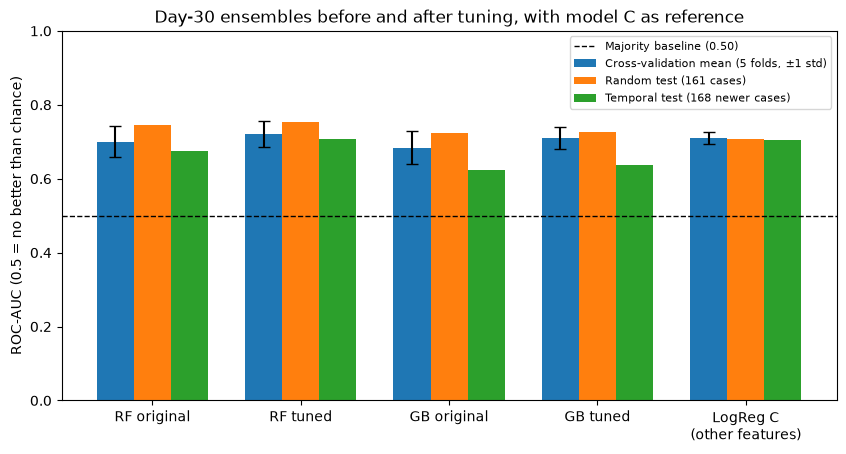

In [25]:
chart_rows = list(cv_summary)
positions = list(range(len(chart_rows)))
width = 0.25

plt.figure(figsize=(10, 4.8))
plt.bar([p - width for p in positions], results_table.loc[chart_rows, "CV ROC-AUC mean"], width,
        yerr=results_table.loc[chart_rows, "CV ROC-AUC std"], capsize=4, label="Cross-validation mean (5 folds, ±1 std)")
plt.bar(positions, results_table.loc[chart_rows, "Random ROC-AUC"], width, label="Random test (161 cases)")
plt.bar([p + width for p in positions], results_table.loc[chart_rows, "Temporal ROC-AUC"], width,
        label="Temporal test (168 newer cases)")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1, label="Majority baseline (0.50)")
plt.xticks(positions, ["RF original", "RF tuned", "GB original", "GB tuned", "LogReg C\n(other features)"])
plt.ylim(0, 1)
plt.ylabel("ROC-AUC (0.5 = no better than chance)")
plt.title("Day-30 ensembles before and after tuning, with model C as reference")
plt.legend(loc="upper right", fontsize=8)
plt.show()

## 11. Leakage Check

I change the activity and resource of **every event after each case's day-30 cutoff** to fake values (cohort and
cutoffs fixed) and rebuild the ensemble features (7 counts + 15 activity indicators) and the model C features. If the
features only use events up to day 30, nothing may change.

In [26]:
check_activities = select_activities(first30, random_train_ids)
check_groups = select_groups(first30, random_train_ids)
all_ids = list(counts.index)

changed = df.copy()
after_day30 = changed["time:timestamp"] > changed["case:concept:name"].map(active["prediction_time"])
changed.loc[after_day30, "concept:name"] = "FAKE_ACTIVITY"
changed.loc[after_day30, "org:resource"] = "FAKE_RESOURCE"
changed_first30 = add_activity_groups(events_by_day30(changed, active))

In [27]:
original_c = make_X(all_ids, "C. Combined", check_activities, check_groups)

changed_counts = count_features(changed_first30, active).loc[all_ids]
changed_ensemble = changed_counts.join(activity_flags(changed_first30, check_activities, all_ids))
changed_c = changed_ensemble.join(group_flags(changed_first30, check_groups, all_ids))
changed_c = changed_c.join(highest_main_stage(changed_first30, all_ids))

print("Events changed:", after_day30.sum())
print("Ensemble features unchanged:", changed_ensemble.equals(make_X(all_ids, "A. Original", check_activities, check_groups)))
print("Model C features unchanged:", changed_c.equals(original_c))

Events changed: 26120
Ensemble features unchanged: True
Model C features unchanged: True


**What this check shows, and what it does not.**

1. **Feature timing:** the features use only events timestamped on or before day 30. The check above tests this in code.
2. **Retrospective cohort selection:** a case is included only if its last recorded event is after day 30, which is
   only known afterwards. The check does not change this.
3. **Real-world knowledge of open cases:** a live system would need to know which cases are really still open at
   day 30. This log does not show that reliably.

A successful feature-timing check therefore does **not** show that the model is ready for real use.

## 12. Interpretation

**The original models reproduce notebooks 12 and 14 exactly**, so the before-and-after comparison is fair.

**Tuned settings (chosen by cross-validation only).**

- Random Forest: grid 9 = 200 trees, `max_depth=5`, `min_samples_leaf=1` (cross-validation ROC-AUC 0.720).
- Gradient Boosting: grid 2 = 50 trees, `learning_rate=0.05`, `max_depth=3` (cross-validation ROC-AUC 0.710).

**What the grids show.** For Random Forest, `max_depth=5` gave the best results (0.716–0.720). Trees without a depth
limit and with `min_samples_leaf=1` were clearly worse (0.672 and 0.675): such trees can fit the training cases too
closely. For Gradient Boosting, all eight combinations were between 0.682 and 0.710, and the deeper trees
(`max_depth=3`) were better.

**Cross-validation before and after tuning.** Random Forest rose from 0.701 to 0.720, and Gradient Boosting from 0.684
to 0.710. Both gains (0.019 and 0.026) are smaller than the fold-to-fold variation (standard deviations 0.029–0.044), and
the best score of a grid is slightly optimistic, so cross-validation alone does not show a clear improvement.

**Test sets (not used for any choice).**

- Tuned Random Forest improved on both tests: random 0.752 (original 0.745) and temporal 0.709 (original 0.674).
- Tuned Gradient Boosting changed little: random 0.726 (0.723) and temporal 0.636 (0.624); it stays clearly weaker on the
  newer cases.

**Warnings are still unstable.** Tuned Random Forest flags 113 of 161 random-test cases (recall 0.842) but only 47 of 168
temporal-test cases (precision 0.894, recall 0.42), so on the newer cases it misses most long cases. Tuning did not fix
this; model C finds more long cases there (recall 0.50, 59 cases flagged).

**Compared with model C.** Tuned Random Forest and model C now rank cases about equally well: cross-validation 0.720 vs
0.710, random test 0.752 vs 0.708, temporal test 0.709 vs 0.705. They use different features, so this is not a pure
tuning comparison. Model C is more stable across the folds (standard deviation 0.017 vs 0.035), its warnings change less
between the tests, and it is easier to explain.

**Answer.** Small, fixed grids improved both ensembles a little, especially Random Forest, but the gains are within the
cross-validation variation and the test sets have been used before. Tuning made Random Forest competitive with model C,
not clearly better. The day-30 signal remains **modest**, and the warnings are **not ready for operational use**.

## 13. Limitations

- The cohort is **retrospective**, and the 63-day threshold is **exploratory** (chosen with all completed cases in
  `01_EDA.ipynb`).
- The random and temporal test cases were **already used** in notebooks 07–16. The temporal check is a chronological
  robustness check, **not** an independent final validation (138 of its 168 test cases were random-split training cases).
- The grids are small and were fixed in advance; other settings could give different results. The best cross-validation
  score of a grid is slightly optimistic.
- Model C uses a different feature set from the ensembles, so C versus the ensembles is not a comparison of tuning alone.
- Feature importances or model results are **not** causal explanations.
- One Dutch municipality; not SPAR or Montenegro data.